# IMPORT LIBRARY

In [28]:
import pandas as pd
import numpy as np
import joblib
import os

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# LOAD DATASET

In [29]:
df = pd.read_csv("../data/processed/data_creditcard_preprocessed.csv")

display(df.head())

print("Dataset Shape:", df.shape)

print(df["Class"].value_counts())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Amount_log,Hour_sin,Hour_cos
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,5.014760,0.0,1.0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,1.305626,0.0,1.0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,5.939276,0.0,1.0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,4.824306,0.0,1.0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,4.262539,0.0,1.0


Dataset Shape: (283726, 34)
Class
0    283253
1       473
Name: count, dtype: int64


In [30]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (283726, 33)
Target: (283726,)


# TRAIN-TEST SPLIT

In [31]:
# Sort transactions based on time
df = df.sort_values("Time").reset_index(drop=True)

# Determine 80% training boundary
split_index = int(len(df) * 0.8)

# Split features and target
X = df.drop(columns=["Class"])
y = df["Class"]

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Fraud Distribution:")
print(y_train.value_counts())

print("\nTesting Fraud Distribution:")
print(y_test.value_counts())

Training Data: (226980, 33)
Testing Data: (56746, 33)

Training Fraud Distribution:
Class
0    226581
1       399
Name: count, dtype: int64

Testing Fraud Distribution:
Class
0    56672
1       74
Name: count, dtype: int64


# MODEL TRAINING

## Logistic Regression

In [32]:
# Initialize Logistic Regression
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Training
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


c:\Users\Fawwaz\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Random Forest

In [33]:
# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Training
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


## XGBoost

In [34]:
# Calculate class imbalance ratio
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_weight = negative / positive

print("Scale Pos Weight:", scale_weight)

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

# Training
xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

Scale Pos Weight: 567.8721804511279
XGBoost training completed!


# EVALUASI MODEL

In [35]:
def evaluate_model(model, X_test, y_test):

    # Predict class
    y_pred = model.predict(X_test)

    # Predict probability
    y_prob = model.predict_proba(X_test)[:, 1]

    results = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    return results

## EVALUASI KETIGA MODEL

In [36]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = {}

for name, model in models.items():

    results[name] = evaluate_model(
        model,
        X_test,
        y_test
    )

# Display comparison
results_df = pd.DataFrame(results).T

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
Logistic Regression,0.9811,0.0592,0.9054,0.1111,0.7344,0.9828
Random Forest,0.9996,0.9636,0.7162,0.8217,0.8163,0.9850
XGBoost,0.9995,0.8056,0.7838,0.7945,0.8139,0.9858


# VISUALISASI EVALUASI

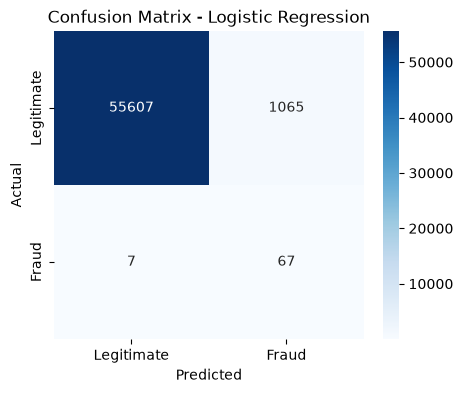

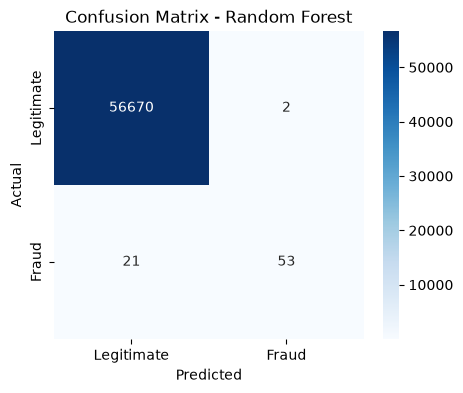

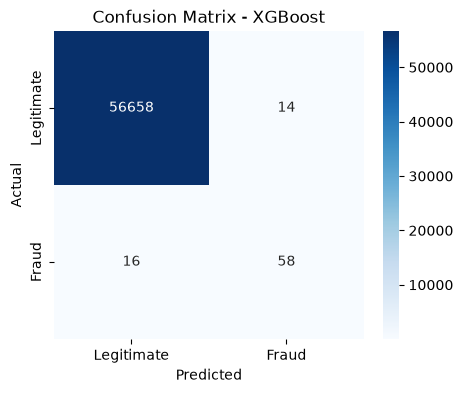

In [37]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

## Membandingkan model

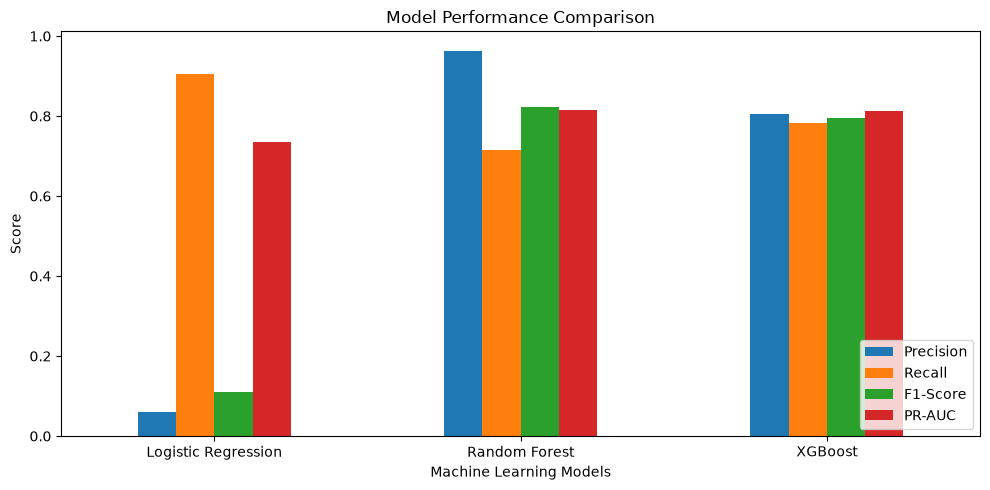

In [38]:
results_df[
    ["Precision", "Recall", "F1-Score", "PR-AUC"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")

plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## MODEL TERBAIK

In [39]:
# Select model with highest PR-AUC
best_model_name = results_df["PR-AUC"].idxmax()

best_model = models[best_model_name]

print("Best Model:", best_model_name)

# Create directory
os.makedirs("models", exist_ok=True)

# Save model
joblib.dump(
    best_model,
    "models/best_fraud_detection_model.pkl"
)

print("Best model successfully saved!")

Best Model: Random Forest
Best model successfully saved!
